In [3]:

# Install IBL ONE API
%pip -q install -U ONE-api

from one.api import ONE
import pandas as pd
import numpy as np

# Connect using the public IBL credentials
one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

PROJECT = "angelaki_mouseASD"
RELEASE = "2025_Q3_Noel_et_al_Autism"

print("Connected to IBL OpenAlyx")
print("Project:", PROJECT)
print("Release:", RELEASE)


Connected to IBL OpenAlyx
Project: angelaki_mouseASD
Release: 2025_Q3_Noel_et_al_Autism


In [4]:

# Find all probe insertions belonging to the Angelaki ASD project
insertions = one.search_insertions(project=PROJECT)

print("Total probe insertions:", len(insertions))
print("First five insertion IDs:")
for pid in insertions[:5]:
    print(pid)

# Keep the insertion list for the next steps
pids = [str(pid) for pid in insertions]


/usr/local/lib/python3.13/dist-packages/one/webclient.py:1053: RuntimeWarning: The shared public account will be retired soon. Register your own account at https://openalyx.internationalbrainlab.org/signup
  emit(message)


Total probe insertions: 364
First five insertion IDs:
71275b79-12f3-42a0-8963-43f6381fbd4a
a24cad0d-9d17-472c-aac2-f5ee4a126bb5
8a05e4d5-a860-4947-81d5-9a2c90779d44
617f42c7-9580-4f25-a466-ec8989d89452
c4a5fed9-ff3b-4b73-8a79-38ba966c0093


In [5]:

# Select one example probe insertion
pid = pids[0]

# Read insertion metadata without downloading raw signals
insertion_info = one.alyx.rest(
    "insertions", "read", id=pid
)

print("Insertion ID:", pid)
print("Probe name:", insertion_info.get("name"))

# Resolve the associated session
session_ref = insertion_info.get("session")
eid = (
    session_ref.split("/")[-2]
    if isinstance(session_ref, str) and "/" in session_ref
    else str(session_ref)
)

print("Session ID:", eid)

# List available files (metadata only)
datasets = one.list_datasets(
    eid, details=True
)

df = pd.DataFrame(datasets)

print("Total dataset entries:", len(df))
print("Available columns:", df.columns.tolist())

display(df.head(10))


Insertion ID: 71275b79-12f3-42a0-8963-43f6381fbd4a
Probe name: probe00
Session ID: 3da15f76-b31b-4ca7-a25c-c46cb8e40a06
Total dataset entries: 127
Available columns: ['file_size', 'hash', 'exists', 'rel_path', 'default_revision', 'qc']


,file_size,hash,exists,rel_path,default_revision,qc
id,,,,,,
02c09856-5183-401e-977e-101b94694166,86640,292e611afefee0d24bc93e7e45b2800d,True,raw_ephys_data/probe01/_spikeglx_sync.polariti...,True,NOT_SET
043642a1-de53-4eb3-a913-1922461f6e93,13900456,11eb9ba41106ef32b55243dd52be1f63,True,alf/_ibl_wheel.timestamps.npy,True,NOT_SET
0598f25b-fa55-4b77-8e6d-487b0224ce31,86640,3ca33ded4d6b5fc4dcc2a7a17f69e2b1,True,raw_ephys_data/probe00/_spikeglx_sync.times.pr...,True,NOT_SET
0778952c-5693-420b-9b52-af168406aac6,37000368,d52bff48b96dddc235b022f6b96688f0,True,alf/probe01/pykilosort/spikes.samples.npy,True,NOT_SET
08b47448-9564-4958-b7d9-96974663d2c0,26434960,5c64643d163456c0bcd7e1ab643b6e02,True,alf/probe00/pykilosort/spikes.amps.npy,True,NOT_SET
0a3a82af-cf08-40ed-b075-1e7a9fd4084d,33386,0c232d2e5e6f5b7b1276b5d31ea77984,True,alf/probe00/pykilosort/#2024-03-12#/clusters.m...,False,NOT_SET
0f644cfd-ed29-4980-91d3-20e0a5647675,13806,f9ad7f0a697b84d3a20e5f09f5b1d43b,True,alf/probe01/pykilosort/clusters.uuids.csv,True,NOT_SET
11574cdc-14c4-40d5-b5f8-2ecc18e4443f,13217544,5841365092da533766f88116c32c3f7d,True,alf/probe00/pykilosort/spikes.clusters.npy,True,NOT_SET
12631122-7a61-468e-accd-de9fcae81041,3867330,83532f8396d224f141d602341f0012a0,True,alf/_ibl_bodyCamera.dlc.pqt,True,NOT_SET


In [6]:

# Search dataset metadata for continuous LF recordings
# and existing spectral summaries

df["dataset_path"] = df.get(
    "rel_path",
    pd.Series("", index=df.index)
).fillna("").astype(str)

lf_mask = df["dataset_path"].str.contains(
    r"\.lf\.|SpectralDensityLF|ephysTimeRmsLF",
    case=False,
    regex=True
)

lf_datasets = df.loc[lf_mask].copy()

print("Potential LFP-related files:", len(lf_datasets))
display(lf_datasets)


Potential LFP-related files: 14


,file_size,hash,exists,rel_path,default_revision,qc,dataset_path
id,,,,,,,
2c9239a9-5db3-42ba-b316-9c5435aeeb7a,2542668,1dc5dc4adfb7e13d5579aff7409701ec,True,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.r...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.r...
3bf46231-0b12-4f63-972c-80d017b9c0e6,2976804902,61db2b49b0a26b4c1025a1518b4ad34c,True,raw_ephys_data/probe00/_spikeglx_ephysData_g0_...,True,NOT_SET,raw_ephys_data/probe00/_spikeglx_ephysData_g0_...
728ac514-0788-4ff5-aacc-44c567adbc5e,2180,f3ffe62ed24d19c0979861b4308a9d00,True,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...
769884b3-f91f-4028-820e-8ee55c2e7ec5,6732,2dd9d05c37db730f0478295c292c0d4b,True,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.t...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.t...
81ecce23-d925-4772-b6ad-95cd8e9294f7,790148,70dfa3c0125be79645dcbadcec3484a7,True,raw_ephys_data/probe00/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysSpectralDen...
901d28ab-db2a-44bb-aa37-e97157ddffce,13904,09997db193dc51e60295f0e6f50f8e9e,True,raw_ephys_data/probe01/_spikeglx_ephysData_g0_...,True,NOT_SET,raw_ephys_data/probe01/_spikeglx_ephysData_g0_...
9e36dd4e-8ae3-4d9e-a3ee-f8fa60c16586,6732,aeaa70e86fbe700e57a30d8aa35e673f,True,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.t...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.t...
b72e2839-8d78-49e9-bc93-4e562a852dd7,2542668,fc53dcdae399ab3d70f3f19356456955,True,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.r...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.r...
c124fc1a-7678-42f5-b7fe-7bfaf84964e4,790148,ae958419415d176df564634a4175f321,True,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...


In [7]:

# Display complete LFP-related filenames
pd.set_option("display.max_colwidth", None)

lf_files = df[
    df["rel_path"].str.contains(
        r"\.lf\.|SpectralDensityLF|TimeRmsLF",
        case=False,
        regex=True,
        na=False
    )
].copy()

lf_files["size_MB"] = (
    lf_files["file_size"] / 1024**2
).round(2)

print("LFP-related files:")
print("Total:", len(lf_files))

for _, row in lf_files.iterrows():
    print(
        f"{row['size_MB']:>9.2f} MB | "
        f"{row['rel_path']}"
    )


LFP-related files:
Total: 14
     2.42 MB | raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.rms.npy
  2838.90 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.cbin
     0.00 MB | raw_ephys_data/probe01/_iblqc_ephysSpectralDensityLF.freqs.npy
     0.01 MB | raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.timestamps.npy
     0.75 MB | raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.power.npy
     0.01 MB | raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.meta
     0.01 MB | raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.timestamps.npy
     2.42 MB | raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.rms.npy
     0.75 MB | raw_ephys_data/probe01/_iblqc_ephysSpectralDensityLF.power.npy
     0.00 MB | raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.freqs.npy
     0.15 MB | raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.ch
     0.15 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.ch
     0.01 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.i

In [8]:

# Retrieve session metadata
session_info = one.alyx.rest(
    "sessions", "read", id=eid
)

print("Session ID:", eid)
print("Subject:", session_info.get("subject"))
print("Date:", session_info.get("start_time"))
print("Project:", session_info.get("projects"))
print("Number of trials:", session_info.get("n_trials"))

# Retrieve subject metadata
subject_name = session_info.get("subject")

subject_info = one.alyx.rest(
    "subjects", "read", id=subject_name
)

print("\nSubject metadata:")
for key in [
    "nickname",
    "sex",
    "birth_date",
    "genotype",
    "line",
    "strain"
]:
    print(f"{key}: {subject_info.get(key)}")


Session ID: 3da15f76-b31b-4ca7-a25c-c46cb8e40a06
Subject: FMR031
Date: 2022-03-25T10:35:25.897863
Project: ['angelaki_mouseASD']
Number of trials: 658

Subject metadata:
nickname: FMR031
sex: M
birth_date: 2021-11-16
genotype: []
line: None
strain: None


In [9]:

# Load precomputed LFP spectral density
# These files are small; raw LFP will not be downloaded.

PROBE = "probe00"

lf_psd = one.load_object(
    eid,
    "ephysSpectralDensityLF",
    collection=f"raw_ephys_data/{PROBE}"
)

print("Available PSD fields:")
print(list(lf_psd.keys()))

for key, value in lf_psd.items():
    print(
        f"{key}: shape={np.shape(value)}, "
        f"dtype={getattr(value, 'dtype', 'unknown')}"
    )

freqs = np.asarray(lf_psd["freqs"])
power = np.asarray(lf_psd["power"])

print("\nFrequency range:", freqs.min(), "-", freqs.max(), "Hz")
print("Frequency resolution:", np.median(np.diff(freqs)), "Hz")
print("PSD array shape:", power.shape)


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.power.npy: 100%|██████████| 790k/790k [00:00<00:00, 2.26MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.freqs.npy: 100%|██████████| 2.18k/2.18k [00:00<00:00, 11.7kB/s]


Available PSD fields:
['power', 'freqs']
power: shape=(513, 385), dtype=float32
freqs: shape=(513,), dtype=float32

Frequency range: 0.0 - 1250.0 Hz
Frequency resolution: 2.4414062 Hz
PSD array shape: (513, 385)


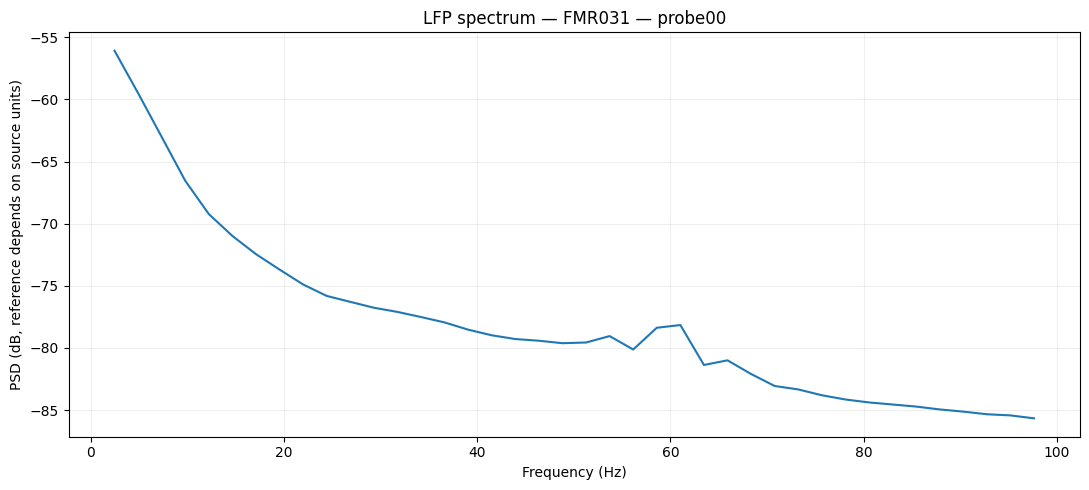

In [10]:

import matplotlib.pyplot as plt

# Detect which PSD axis contains frequency bins
if power.shape[0] == len(freqs):
    psd_by_frequency = power
elif power.shape[1] == len(freqs):
    psd_by_frequency = power.T
else:
    raise ValueError("Cannot identify frequency axis.")

# Calculate median PSD across channels for visualization
median_psd = np.nanmedian(psd_by_frequency, axis=1)

# Plot frequency spectrum
mask = (freqs >= 1) & (freqs <= 100)

plt.figure(figsize=(11, 5))
plt.plot(
    freqs[mask],
    10 * np.log10(np.maximum(median_psd[mask], 1e-30)),
    linewidth=1.5
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB, reference depends on source units)")
plt.title(f"LFP spectrum — {subject_name} — {PROBE}")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [11]:

# Download LF metadata only (not the raw .lf.cbin file)

meta_file = one.load_dataset(
    eid,
    "_spikeglx_ephysData_g0_t0.imec0.lf.meta",
    collection="raw_ephys_data/probe00",
    download_only=True
)

# Parse SpikeGLX metadata
metadata = {}

with open(meta_file, "r", encoding="utf-8-sig") as f:
    for line in f:
        if "=" in line:
            key, value = line.strip().split("=", 1)
            metadata[key] = value

print("Sampling rate:", metadata.get("imSampRate"), "Hz")
print("Channels saved:", metadata.get("nSavedChans"))
print("Recording duration:", metadata.get("fileTimeSecs"), "s")
print("Probe type:", metadata.get("imDatPrb_type"))

print("\nOther useful metadata:")
for key in ["imAiRangeMax", "imMaxInt", "snsApLfSy"]:
    print(f"{key}: {metadata.get(key)}")


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.meta: 100%|██████████| 13.9k/13.9k [00:00<00:00, 101kB/s]

Sampling rate: 2500 Hz
Channels saved: 385
Recording duration: 5406.7384 s
Probe type: 0

Other useful metadata:
imAiRangeMax: 0.6
imMaxInt: None
snsApLfSy: 0,384,1


In [12]:

# Inspect anatomical channel datasets for both probes.
# Metadata only: no raw electrophysiology downloads.

channel_files = df[
    df["rel_path"].str.contains(
        r"channels\.|electrodeSites|probes\.",
        case=False,
        regex=True,
        na=False
    )
].copy()

channel_files["size_KB"] = (
    channel_files["file_size"] / 1024
).round(1)

print("Anatomical/channel datasets:")
print("Total:", len(channel_files))

for _, row in channel_files.iterrows():
    print(
        f"{row['size_KB']:>9.1f} KB | "
        f"{row['rel_path']}"
    )

print("\nCurrent insertion metadata:")
print("Probe:", insertion_info.get("name"))
print("Histology:", insertion_info.get("json"))
print("QC:", insertion_info.get("qc"))


Anatomical/channel datasets:
Total: 30
      3.1 KB | alf/probe00/electrodeSites.localCoordinates.npy
      3.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.rawSpikeRates.npy
      3.1 KB | alf/probe00/electrodeSites.brainLocationIds_ccf_2017.npy
      3.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.labels.npy
     46.8 KB | alf/probe01/pykilosort/clusters.waveformsChannels.npy
      4.6 KB | alf/probe00/pykilosort/channels.mlapdv.npy
      3.1 KB | raw_ephys_data/probe00/_iblqc_ephysChannels.rawSpikeRates.npy
      3.1 KB | alf/probe00/pykilosort/channels.rawInd.npy
      1.7 KB | alf/probe00/pykilosort/clusters.channels.npy
     46.8 KB | alf/probe01/pykilosort/templates.waveformsChannels.npy
   1349.6 KB | alf/probe00/pykilosort/_phy_spikes_subset.channels.npy
      6.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.apRMS.npy
     84.6 KB | raw_ephys_data/probe00/_spikeglx_sync.channels.probe00.npy
      3.1 KB | raw_ephys_data/probe00/_iblqc_ephysChannels.labels.npy
    

In [13]:

# Compare datasets available for the two simultaneous probes.

for probe in ["probe00", "probe01"]:
    probe_files = df[
        df["rel_path"].str.contains(
            f"/{probe}/",
            regex=False,
            na=False
        )
    ]

    lf_raw = probe_files[
        probe_files["rel_path"].str.endswith(
            ".lf.cbin", na=False
        )
    ]

    anatomy = probe_files[
        probe_files["rel_path"].str.contains(
            "channels.", regex=False, na=False
        )
    ]

    print(f"\n{probe}")
    print("Raw LF files:", len(lf_raw))
    print("Channel anatomy files:", len(anatomy))
    print("All associated datasets:", len(probe_files))



probe00
Raw LF files: 1
Channel anatomy files: 7
All associated datasets: 49

probe01
Raw LF files: 1
Channel anatomy files: 7
All associated datasets: 49
